# Developing the NWA12 Supergrid, Land Mask, and Topo 

In [1]:
# Functional Packages
import xarray as xr 
import numpy as np  
from scipy.spatial import cKDTree
from datetime import datetime
import os

# Visualization Packages
import matplotlib as mpl
import matplotlib.pyplot as plt

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# Create Output Folders 

def make_dir(dir_str):
    if not os.path.exists(dir_str):
        os.makedirs(dir_str)
        print("new directory created: "+ dir_str)

make_dir("input_files")
make_dir("plots")

## Define Helpful Grid Functions

In [3]:
def spherical2cartesian(lon, lat):
    '''
    Convert spherical coordinates to cartesian coordinates 
    '''
    R_earth=6378136 # meters
    lonr = np.deg2rad(lon)
    latr = np.deg2rad(lat)
    x = R_earth * np.cos(latr) * np.cos(lonr)
    y = R_earth * np.cos(latr) * np.sin(lonr)
    z = R_earth * np.sin(latr)
    return x, y, z

In [4]:
def create_tree(lon, lat):
    '''
    Create a K-d tree from the spherical coordinates, which is good for spatial queries, like nearest neighbor search
    '''
    # Convert spherical coordinates to cartesian coordinates
    x, y, z = spherical2cartesian(lon, lat)

    # Stack - flatten the cartesian coordinates in 1D arrays
    x_stack = x.stack(points=x.dims).values
    y_stack = y.stack(points=y.dims).values
    z_stack = z.stack(points=z.dims).values

    # Construct KD-tree
    tree = cKDTree(np.column_stack((x_stack, y_stack, z_stack)))

    # Return tree
    return tree

In [5]:
def find_nearest(lon, lat, lon_pt, lat_pt):
    '''
    Find the nearest point to lon_pt, lat_pt in the grid defined by lon, lat
    '''
    # Create a tree from the grid
    tree = create_tree(lon, lat)

    # Get Cartesian coordinates of the point of interest
    xp, yp, zp = spherical2cartesian(lon_pt, lat_pt)

    # Find nearest index
    _, idx = tree.query(np.column_stack((xp, yp, zp)))
    
    #idx = np.unique(idx) # Remove duplicates

    # Format and return the index
    idx = np.unravel_index(idx, lon.shape)
    Iidx = idx[1]
    Jidx = idx[0]
    return Iidx, Jidx

### Find the extent of the GFDL NWA12 Grid

In [7]:
# Read in GFDL NWA12 Grid

ds = xr.open_dataset('/glade/work/gmarques/Projects/NWA12/grid/ocean_hgrid.nc')

In [8]:
# Find the extent of the grid in the longitude

lon_min = np.floor(ds.x.min())
lon_max = np.ceil(ds.x.max())

In [9]:
# Find the extent of the grid in the latitude

lat_min = np.floor(ds.y.min())
lat_max = np.ceil(ds.y.max())

In [10]:
print(lon_min, lon_max, lat_min, lat_max)

<xarray.DataArray 'x' ()>
array(-99.) <xarray.DataArray 'x' ()>
array(-36.) <xarray.DataArray 'y' ()>
array(5.) <xarray.DataArray 'y' ()>
array(59.)


## Read in OS's MOM6 global 1/12 degree supergrid and topo/mask (modelgrid)

In [6]:
# Reed in Global Supergrid

dsg = xr.open_dataset('/glade/work/fredc/cesm/grid/MOM6/tx1_12v1/gridgen/ocean_hgrid_trimmed.nc')

In [7]:
# Read in Global Topography and Mask

dsg_topo = xr.open_dataset('/glade/work/bryan/MOM6-data-files/Topography/tx1_12v1/topo.sub25.tx1_12v1.srtm.edit1.SmL1.0_C1.0.nc')

## Find indices in the global grid that most closely match the extent of the GFDL NWA12 grid

In [13]:
I_llc, J_llc = find_nearest(dsg.x, dsg.y, lon_min, lat_min)


In [14]:
I_urc, J_urc =  find_nearest(dsg.x, dsg.y, lon_max, lat_max)


KeyboardInterrupt: 

In [13]:
print("LLC:",I_llc, J_llc)
print("URC:",I_urc, J_urc)

LLC: [4512] [3479]
URC: [6049] [5066]


## Manually select grid extent for a final grid size that plays well with MPI

In [8]:
I_llc = 4536
J_llc = 3484

In [9]:
I_urc = 6016
J_urc = 5044

## Cut grid to manual extent and save supergrid file

In [10]:
# Cut grid

ds_nwa = dsg.isel(nx=slice(I_llc,I_urc)).isel(ny=slice(J_llc,J_urc))

In [12]:
# Cut grid

ds_nwa = ds_nwa.isel(nxp=slice(I_llc,I_urc+1)).isel(nyp=slice(J_llc,J_urc+1))

In [13]:
# Add metadata

ds_nwa = ds_nwa.assign_attrs({'Description':'MOM6 NCAR NWA12', 'Created':datetime.now().isoformat()})

In [1]:
# Show grid file locally

print(ds_nwa)

NameError: name 'ds_nwa' is not defined

In [19]:
# Save grid file locally

ds_nwa.to_netcdf('input_files/ocean_hgrid.nc')

## Create regional Mask and Topo files

In [14]:
# Mask and Topo files are on the model grid, which is a division of 2 of the supergrid in each dimension

i1 = I_llc // 2
j1 = J_llc // 2

nx = (I_urc - I_llc) // 2
ny = (J_urc - J_llc) // 2

i2 = i1 + nx
j2 = j1 + ny

In [74]:
print(dsg_topo
      )

<xarray.Dataset>
Dimensions:             (lonh: 4320, lath: 3240, lonq: 4321, latq: 3241)
Coordinates:
  * lonh                (lonh) float64 -287.0 -286.9 -286.8 ... 72.88 72.96
  * lath                (lath) float64 -80.06 -80.04 -80.03 ... 89.95 89.98
  * lonq                (lonq) float64 -287.0 -286.9 -286.8 ... 72.83 72.92 73.0
  * latq                (latq) float64 -80.06 -80.05 -80.04 ... 89.96 89.98
Data variables: (12/15)
    geolon              (lath, lonh) float64 ...
    geolat              (lath, lonh) float64 ...
    geolonb             (latq, lonq) float64 ...
    geolatb             (latq, lonq) float64 ...
    z                   (lath, lonh) float32 ...
    ocn_frac            (lath, lonh) float32 ...
    ...                  ...
    D2_mean             (lath, lonh) float32 ...
    D_min               (lath, lonh) float32 ...
    D_max               (lath, lonh) float32 ...
    hand_edits          (lath, lonh) int32 ...
    orig_mask           (lath, lonh) int32 ...


In [15]:
# Slice Topo & Mask to NWA12 Grid

topo = dsg_topo['D_interp_L1.0_C1.0'].isel(lonh=slice(i1,i2)).isel(lath=slice(j1,j2))
mask = dsg_topo['mask'].isel(lonh=slice(i1,i2)).isel(lath=slice(j1,j2))
mask_test = mask

In [22]:
ocean_mask = xr.where(topo>0,1,0) # This is how we get mask For Ashley Bathy -=> ocean_mask = xr.where(bathymetry!=np.nan,1,0)
# Get lat lon ocean point that we like.
lat = 40
lon = -60
I, J =  find_nearest(dsg.x, dsg.y, lon, lat)
I_llc, J_llc = find_nearest(dsg.x, dsg.y, lon_min, lat_min)
I_llc, J_llc = I_llc[0], J_llc[0]

I = I[0]
J = J[0]




In [23]:
i1 = I_llc // 2
j1 = J_llc // 2

nx = (I - I_llc) // 2
ny = (J - J_llc) // 2

i2 = i1 + nx
j2 = j1 + ny
print(i2, j2)

2726 2207


In [24]:
from scipy.ndimage import label

res, num_features = label(ocean_mask)

[0 1 2 3]


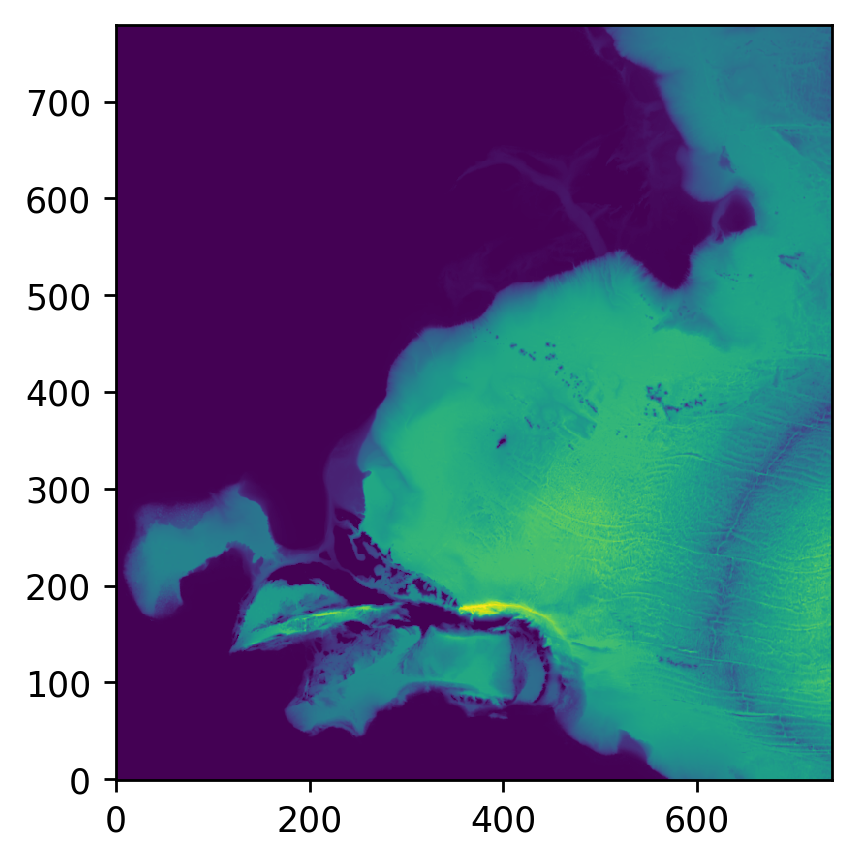

In [25]:
ocean_mask_changed = xr.where(res == res[nx,ny],1,0) 
xr_ocean_mask_changed = xr.DataArray(ocean_mask_changed, coords = ocean_mask.coords, dims = ocean_mask.dims)
print(np.unique(res))
plt.figure(dpi=250)
plt.imshow(xr.where(xr_ocean_mask_changed == 0, 0, topo), origin='lower', interpolation='nearest')

In [93]:
rm6_topo = xr.load_dataset('/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/rm6/hawaii-clean-demo/inputs/bathymetry.nc')
rm6_hgrid = xr.load_dataset('/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/rm6/hawaii-clean-demo/inputs/hgrid.nc')

In [102]:
print(rm6_topo)

<xarray.Dataset>
Dimensions:  (ntiles: 1, ny: 236, nx: 340)
Dimensions without coordinates: ntiles, ny, nx
Data variables:
    depth    (ntiles, ny, nx) float64 5.098e+03 4.713e+03 ... 5.413e+03
Attributes:
    depth:          meters
    standard_name:  bathymetric depth at T-cell centers


In [108]:
ocean_mask_rm6 = xr.where(rm6_topo['depth'][0]>0,1,0) # This is how we get mask For Ashley Bathy -=> ocean_mask = xr.where(bathymetry!=np.nan,1,0)
# Get lat lon ocean point that we like.
lat = 20
lon = 200
I, J =  find_nearest(rm6_hgrid.x, rm6_hgrid.y, lon, lat)
I_llc, J_llc = find_nearest(rm6_hgrid.x, rm6_hgrid.y, lon_min, lat_min)
I_llc, J_llc = I_llc[0], J_llc[0]
I = I[0]
J = J[0]

In [121]:
len(rm6_hgrid['nx'])

680

In [109]:
nx = (I - I_llc) // 2
ny = (J - J_llc) // 2
print(ocean_mask_rm6)

<xarray.DataArray 'depth' (ny: 236, nx: 340)>
array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]])
Dimensions without coordinates: ny, nx


In [110]:
from scipy.ndimage import label

res, num_features = label(ocean_mask_rm6)

In [123]:
ocean_mask_changed = xr.where(res == res[nx,ny],1,0) 
xr_ocean_mask_changed = xr.DataArray(ocean_mask_changed, coords = ocean_mask_rm6.coords, dims = ocean_mask_rm6.dims)
plt.figure(dpi=250)
plt.imshow(xr.where(xr_ocean_mask_changed == 0, 0, topo), origin='lower', interpolation='nearest')

: 

## Manually fill out the mask for unwanted ocean & lake sections

In [20]:
# Mask Hudson Bay and Pacific Ocean 

mask[700:,200:300] = 0
mask[:150,:100] = 0
mask[:120,:165] = 0
mask[:35,:260] = 0
mask[:42,:250] = 0
mask[:55,165:180] = 0
mask[:47,215:235] = 0
mask[:69,300:330] = 0

NameError: name 'mask' is not defined

In [23]:
# Mask Hudson Bay and Pacific Ocean 

topo[700:,200:300] = 0
topo[:150,:100] = 0
topo[:120,:165] = 0
topo[:35,:260] = 0
topo[:42,:250] = 0
topo[:55,165:180] = 0
topo[:47,215:235] = 0
topo[:69,300:330] = 0

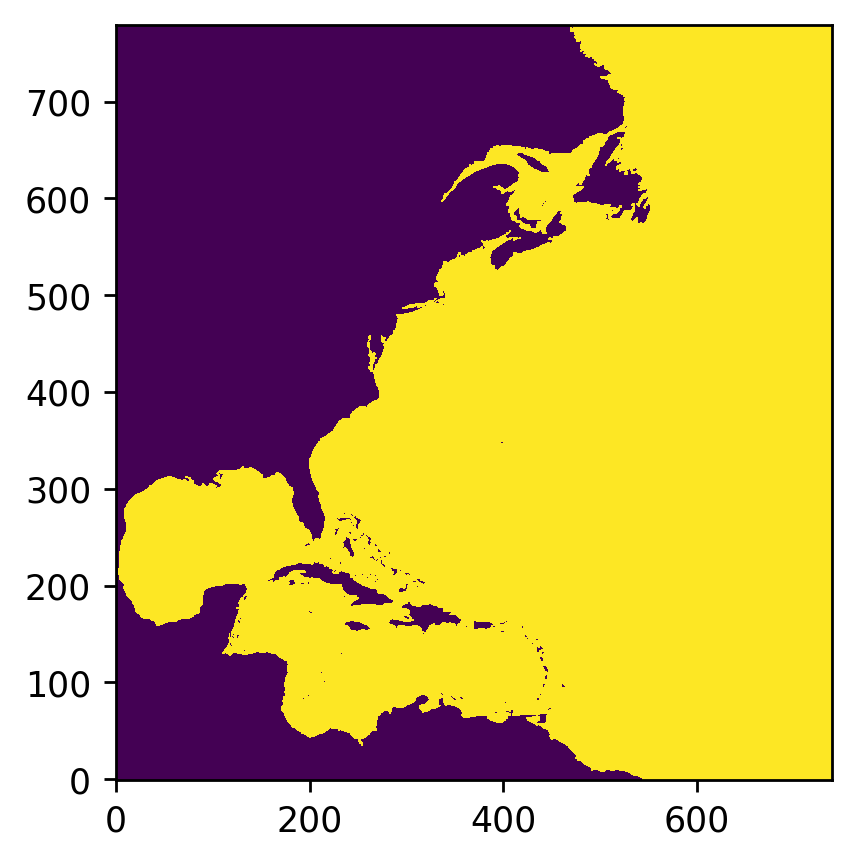

In [24]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask, origin='lower', interpolation='nearest')

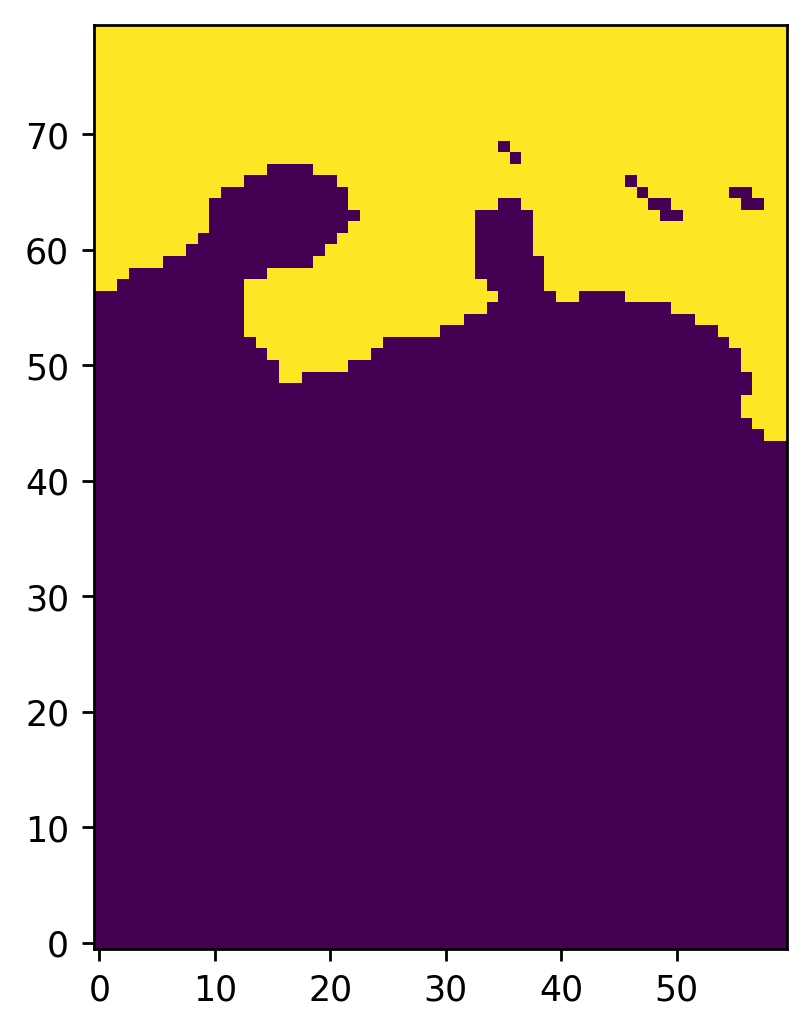

In [ ]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask[20:100,300:360], origin='lower', interpolation='nearest')

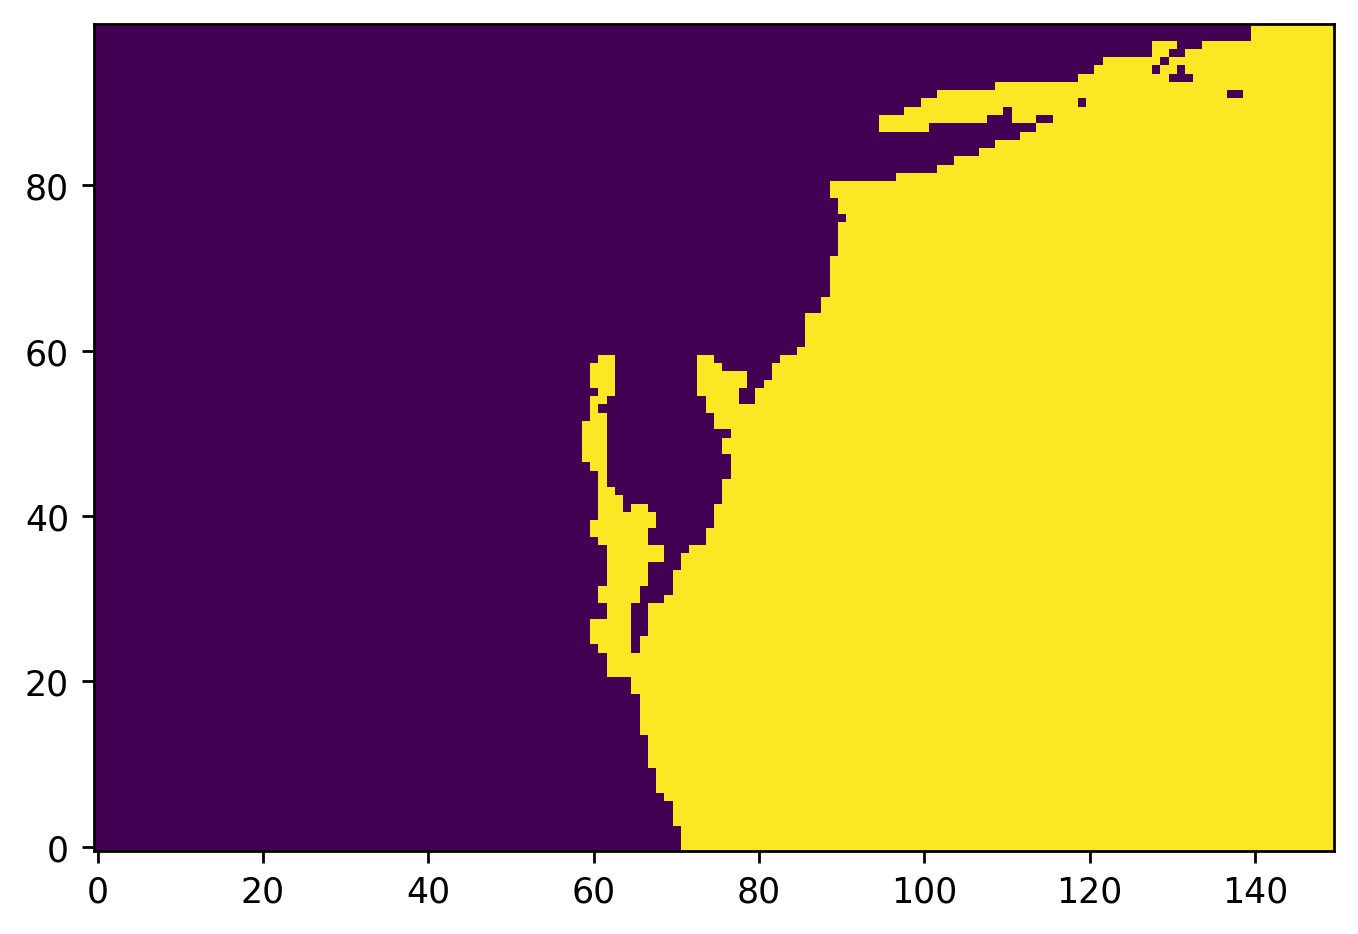

In [ ]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask[400:500,200:350], origin='lower', interpolation='nearest')

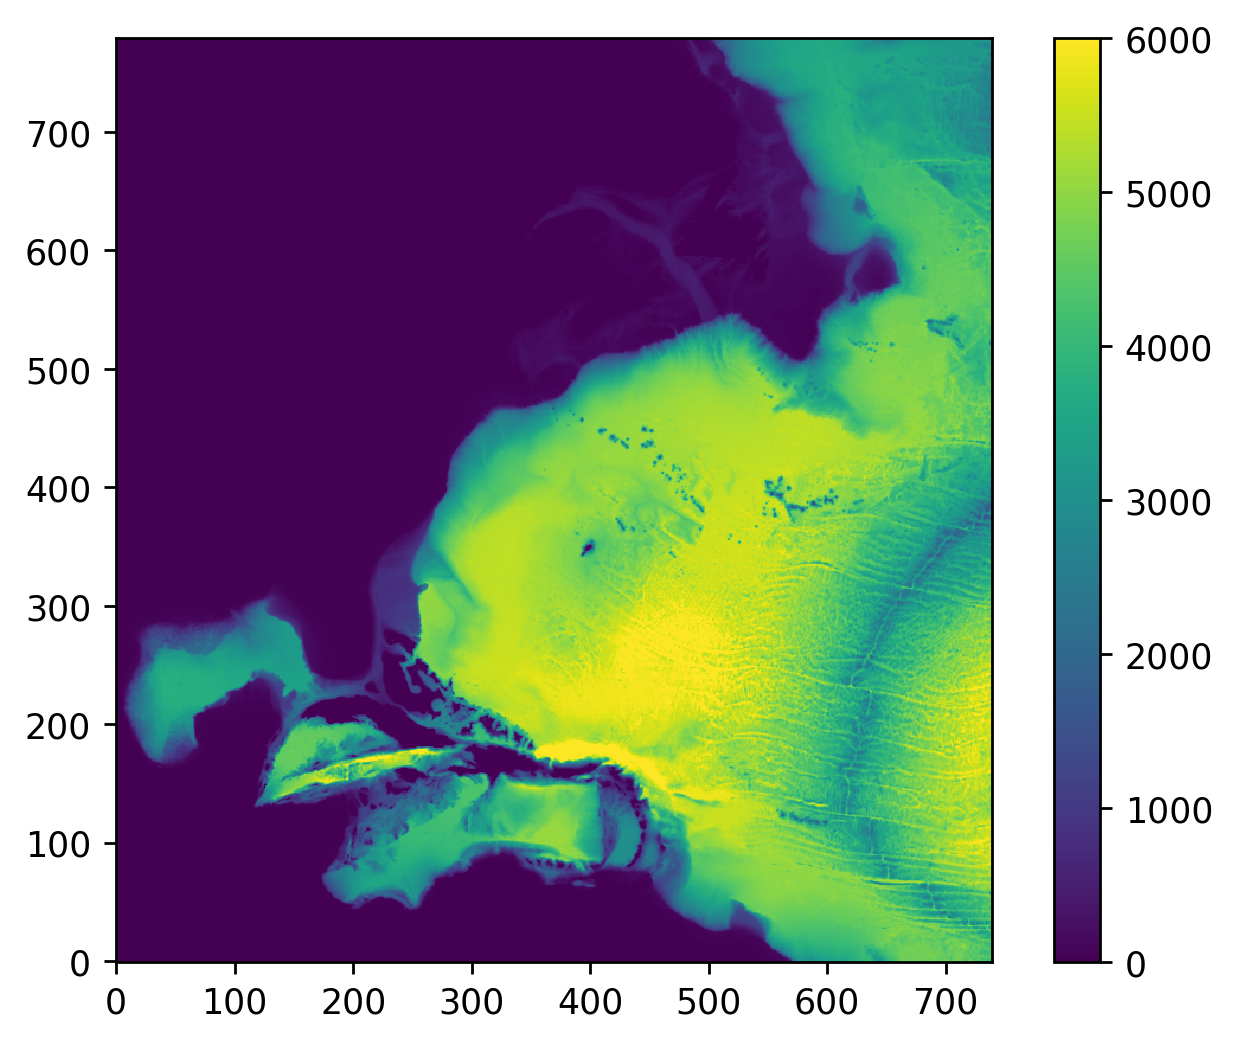

In [ ]:
# Display Topo

plt.figure(dpi=250)
plt.imshow(topo, origin='lower', interpolation='nearest')
plt.clim(0,6000)
plt.colorbar()

## Save Mask and Topo



In [25]:
topo = topo.to_dataset(name='depth')
topo.to_netcdf('input_files/ocean_topo.nc')

In [26]:
mask = mask.to_dataset(name='mask')
mask.to_netcdf('input_files/ocean_mask.nc')